---
Universidad Nacional de Asunción

Facultad de Ingeniería

Ing. Mecatrónica

# **ROBÓTICA I**

---
# **VISIÓN ARTIFICIAL: [Script 11] Detección de frutas con OpenCV y morfología**

**Autor:** Fernando Brunetti

**Fecha:** 08/10/26

**Última modificación:** 08/10/26

---

### **Objetivos**

Al finalizar este script, el estudiante será capaz de:

1. Descargar y utilizar bases de datos públicas de imágenes anotadas de frutas en campo (naranjas y tomates).
2. Elegir un espacio de color adecuado (HSV) y fijar umbrales a partir de la observación de los datos.
3. Segmentar frutas por color y depurar la máscara con operaciones morfológicas (apertura, cierre, relleno de huecos).
4. Separar frutas que se tocan mediante la transformada de distancia y el algoritmo watershed.
5. Describir cada región con contornos y momentos (área, circularidad, solidez, centroide, círculo mínimo) y filtrarlas con reglas.
6. Clasificar las frutas detectadas por madurez y por tamaño con reglas simples, sin aprendizaje automático.
7. Evaluar cuantitativamente el detector contra las anotaciones: entender e interpretar el IoU, la precisión, la exhaustividad y el F1, y el compromiso entre ellas.

### **Enfoque**

Todo el script usa visión artificial **clásica**: no se entrena ningún modelo. Los parámetros (rangos de color, tamaños de los elementos estructurantes, umbrales de forma) los fija el diseñador observando los datos, y las anotaciones de las bases de datos se usan **solo para evaluar**.

Cadena de procesamiento:

**Imagen** → **Espacio de color (HSV)** → **Umbral de color** → **Morfología** → **Distancia + watershed** → **Contornos y descriptores** → **Reglas (forma, madurez, tamaño)** → **Evaluación**

### **0. Preparación del entorno**

In [ ]:
# Robotica I
# Vision artificial
# Script 11
# Objetivo: detectar frutas (naranja, tomate) con segmentacion por color y morfologia
!pip install -q remotezip

import os
import json
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import urllib.request
from remotezip import RemoteZip
from skimage.segmentation import watershed

print('Versión de OpenCV:', cv2.__version__)

ANCHO = 640          # todas las imágenes se procesan a este ancho (px)
CARPETA = 'datos'
os.makedirs(CARPETA, exist_ok=True)


# --------
def mostrar(imagenes, titulos=None, columnas=4, tam=4):
    """Muestra una lista de imágenes BGR o en escala de grises."""
    filas = int(np.ceil(len(imagenes) / columnas))
    plt.figure(figsize=(tam * columnas, tam * filas))
    for i, im in enumerate(imagenes):
        plt.subplot(filas, columnas, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap='gray')
        if titulos:
            plt.title(titulos[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()


# --------
def redimensionar(img, ancho=ANCHO):
    """Escala la imagen a un ancho fijo. Devuelve la imagen y el factor de escala."""
    esc = ancho / img.shape[1]
    return cv2.resize(img, None, fx=esc, fy=esc, interpolation=cv2.INTER_AREA), esc


# --------
def dibujar_cajas(img, cajas, color=(255, 0, 0), grosor=2):
    """Dibuja cajas (x, y, w, h) sobre una copia de la imagen."""
    vis = img.copy()
    for x, y, w, h in cajas:
        cv2.rectangle(vis, (int(x), int(y)), (int(x + w), int(y + h)), color, grosor)
    return vis

Versión de OpenCV: 5.0.0


### **1. Bases de datos**

#### 1.1 Naranjas: *Oranges in the field* (Mendeley Data)

5025 imágenes de 640 × 640 px tomadas con celulares en plantaciones de Sicilia, con distintas condiciones de iluminación, clima y madurez. Cada imagen tiene un archivo `.txt` en formato YOLO: una línea por fruta con `clase xc yc w h` normalizados a [0, 1]. Licencia CC BY-NC 3.0.

El nombre de cada imagen empieza con un prefijo de dos letras que identifica el subconjunto (`MS`, `AC`, `AS`, `ES`, `MC`, ...). Con `prefijo=''` se toman imágenes de todos.

No se descarga la base completa (850 MB): la API pública de Mendeley lista los archivos y se bajan solo `n` imágenes.

**Alternativa automática:** Mendeley Data está detrás de un filtro anti-bots que a veces rechaza las descargas desde Colab. Si eso ocurre, se usan las 57 imágenes de naranjas de *DeepFruits* (Sa et al., 2016), publicadas en Hugging Face por el proyecto AgML, con cajas `[x, y, w, h]` en píxeles.

In [ ]:
API_NARANJAS = 'https://data.mendeley.com/public-api/datasets/93f32zgkxz'
API_DEEPFRUITS = ('https://datasets-server.huggingface.co/rows?dataset=Project-AgML/fruit_detection_worldwide'
                  '&config=default&split=train')
CABECERA = {'User-Agent': 'Mozilla/5.0'}   # sin esta cabecera Mendeley rechaza la descarga


# --------
def leer_url(url):
    """Contenido (bytes) de una URL."""
    with urllib.request.urlopen(urllib.request.Request(url, headers=CABECERA), timeout=120) as r:
        return r.read()


# --------
def falta(ruta):
    """True si el archivo no existe o quedó vacío (descarga interrumpida)."""
    return not os.path.exists(ruta) or os.path.getsize(ruta) == 0


# --------
def descargar(url, ruta):
    """Descarga un archivo si todavía no existe. Se escribe primero en un temporal
    para no dejar archivos a medias si se interrumpe la celda."""
    if falta(ruta):
        with open(ruta + '.tmp', 'wb') as f:
            f.write(leer_url(url))
        os.replace(ruta + '.tmp', ruta)
    return ruta


# --------
def leer_yolo(ruta_txt, ancho, alto):
    """Convierte etiquetas YOLO normalizadas a cajas (x, y, w, h) en píxeles."""
    cajas = []
    with open(ruta_txt) as f:
        for linea in f:
            _, xc, yc, w, h = map(float, linea.split())
            cajas.append(((xc - w / 2) * ancho, (yc - h / 2) * alto, w * ancho, h * alto))
    return cajas


# --------
def naranjas_mendeley(n, prefijo, semilla, carpeta):
    """n imágenes al azar de Oranges in the field. Devuelve [(ruta_imagen, cajas)]."""
    archivos = json.loads(leer_url(API_NARANJAS))['files']
    imagenes = sorted([a for a in archivos if a['filename'].endswith('.jpg') and a['filename'].startswith(prefijo)],
                      key=lambda a: a['filename'])
    etiquetas = {a['filename'][:-4]: a for a in archivos if a['filename'].endswith('.txt')}
    random.Random(semilla).shuffle(imagenes)
    salida = []
    for a in imagenes[:n]:
        base = a['filename'][:-4]
        ruta_img = descargar(a['content_details']['download_url'], os.path.join(carpeta, a['filename']))
        ruta_txt = descargar(etiquetas[base]['content_details']['download_url'], os.path.join(carpeta, base + '.txt'))
        alto, ancho = cv2.imread(ruta_img).shape[:2]
        salida.append((ruta_img, leer_yolo(ruta_txt, ancho, alto)))
    return salida


# --------
def naranjas_deepfruits(n, carpeta, clase_naranja=3):
    """Imágenes de naranjas de DeepFruits (Hugging Face). Devuelve [(ruta_imagen, cajas)]."""
    salida = []
    for desde in range(0, 600, 100):
        filas = json.loads(leer_url(f'{API_DEEPFRUITS}&offset={desde}&length=100'))['rows']
        for fila in filas:
            obj = fila['row']['objects']
            cajas = [tuple(c) for c, k in zip(obj['bbox'], obj['categories']) if k == clase_naranja]
            if cajas and len(salida) < n:
                ruta = descargar(fila['row']['image']['src'], os.path.join(carpeta, f"deepfruits_{fila['row_idx']}.jpg"))
                salida.append((ruta, cajas))
    return salida


# --------
def descargar_naranjas(n=40, prefijo='', semilla=0, fuente='mendeley'):
    carpeta = os.path.join(CARPETA, 'naranjas')
    os.makedirs(carpeta, exist_ok=True)
    if fuente == 'mendeley':
        try:
            return naranjas_mendeley(n, prefijo, semilla, carpeta)
        except Exception as e:
            print(f'No se pudo descargar de Mendeley Data ({e}). Se usa DeepFruits.')
    return naranjas_deepfruits(n, carpeta)


# --------
def cargar_naranjas(lista):
    datos = []
    for ruta_img, cajas in lista:
        img, esc = redimensionar(cv2.imread(ruta_img))
        datos.append({'nombre': os.path.basename(ruta_img), 'img': img,
                      'cajas': [tuple(v * esc for v in c) for c in cajas],
                      'clases': ['naranja'] * len(cajas)})
    return datos


naranjas = cargar_naranjas(descargar_naranjas(n=40))
print(len(naranjas), 'imágenes de naranjas,', sum(len(d['cajas']) for d in naranjas), 'frutas anotadas')

40 imágenes de naranjas, 300 frutas anotadas


#### 1.2 Tomates: *Laboro Tomato*

804 imágenes de tomates en invernadero, anotadas en formato COCO (cajas y polígonos) con seis clases que combinan **tamaño** de la variedad y **madurez**:

| Clase | Significado |
|---|---|
| `b_fully_ripened` / `l_fully_ripened` | maduro (variedad grande / chica) |
| `b_half_ripened` / `l_half_ripened` | semimaduro |
| `b_green` / `l_green` | verde |

Las imágenes son de 3024 × 4032 px. Licencia CC BY-NC-SA 4.0.

El archivo zip pesa 1,6 GB. Con `remotezip` se leen por HTTP solo los archivos que se necesitan (las anotaciones y `n` imágenes del conjunto de prueba).

In [ ]:
URL_TOMATES = 'http://assets.laboro.ai.s3.amazonaws.com/laborotomato/laboro_tomato.zip'
CLASES_TOMATE = {1: 'b_fully_ripened', 2: 'b_half_ripened', 3: 'b_green',
                 4: 'l_fully_ripened', 5: 'l_half_ripened', 6: 'l_green'}


# --------
def descargar_tomates(n=20, semilla=0):
    """Extrae del zip remoto las anotaciones de prueba y n imágenes al azar."""
    with RemoteZip(URL_TOMATES) as z:
        z.extract('laboro_tomato/annotations/test.json', CARPETA)
        with open(os.path.join(CARPETA, 'laboro_tomato/annotations/test.json')) as f:
            anot = json.load(f)
        imagenes = sorted(anot['images'], key=lambda im: im['file_name'])
        random.Random(semilla).shuffle(imagenes)
        for im in imagenes[:n]:
            ruta = 'laboro_tomato/test/' + im['file_name']
            if falta(os.path.join(CARPETA, ruta)):
                z.extract(ruta, CARPETA)
    return anot, imagenes[:n]


# --------
def cargar_tomates(anot, imagenes):
    datos = []
    for im in imagenes:
        img = cv2.imread(os.path.join(CARPETA, 'laboro_tomato/test', im['file_name']))
        img, esc = redimensionar(img)
        anns = [a for a in anot['annotations'] if a['image_id'] == im['id']]
        datos.append({'nombre': im['file_name'], 'img': img,
                      'cajas': [tuple(v * esc for v in a['bbox']) for a in anns],
                      'clases': [CLASES_TOMATE[a['category_id']] for a in anns]})
    return datos


tomates = cargar_tomates(*descargar_tomates(n=20))
print(len(tomates), 'imágenes de tomates,', sum(len(d['cajas']) for d in tomates), 'frutas anotadas')

20 imágenes de tomates, 282 frutas anotadas


In [ ]:
# Anotaciones de referencia (en azul)
ejemplos = naranjas[:4] + tomates[:4]
mostrar([dibujar_cajas(d['img'], d['cajas']) for d in ejemplos], [d['nombre'] for d in ejemplos])

### **2. Espacio de color**

En RGB el color y la iluminación están mezclados en los tres canales: una naranja en sombra y otra al sol tienen valores RGB muy distintos. En **HSV** se separan:

- **H (tono)**: el color en sí. En OpenCV va de 0 a 179 (grados / 2). El rojo está en **ambos extremos** (cerca de 0 y cerca de 179).
- **S (saturación)**: pureza del color. Con S baja (blancos, grises, cielo) el tono no es confiable.
- **V (valor)**: brillo. Es el canal más afectado por las sombras.

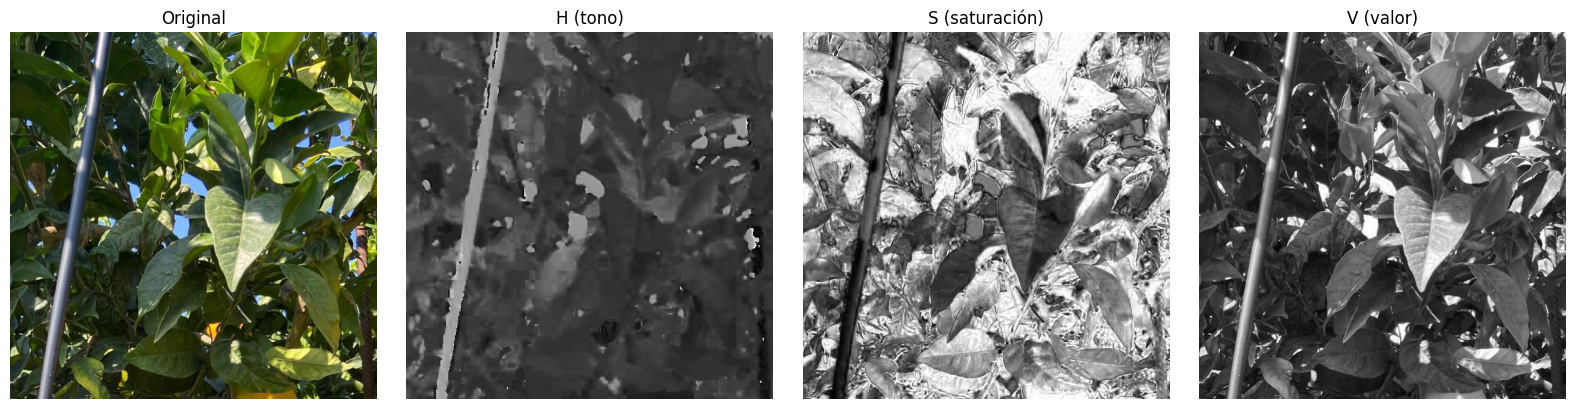

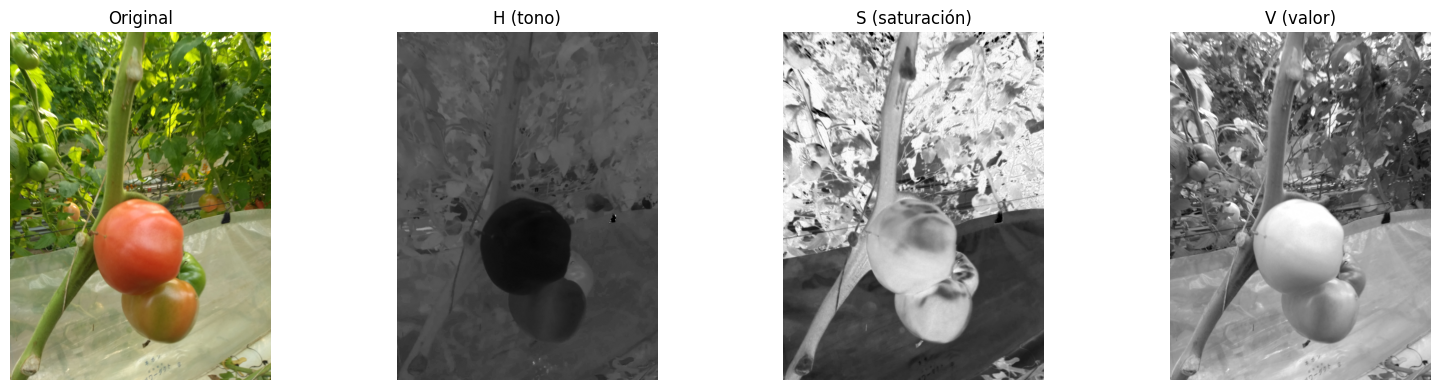

In [ ]:
for d in (naranjas[0], tomates[0]):   # cambiar los índices para ver otras imágenes
    hsv = cv2.cvtColor(d['img'], cv2.COLOR_BGR2HSV)
    mostrar([d['img'], hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]],
            ['Original', 'H (tono)', 'S (saturación)', 'V (valor)'])

#### 2.1 ¿Qué color tienen las frutas?

Antes de fijar umbrales conviene **mirar los datos**: para cada canal (H, S y V) se compara el histograma de los píxeles de las frutas anotadas con el del fondo. Si las dos curvas están separadas, ese canal sirve para segmentar, y el histograma muestra dónde poner el umbral. No es entrenamiento: es la misma inspección que se haría a mano sobre el histograma.

Detalles del cálculo:

- La fruta se aproxima con la **elipse inscripta** en cada caja anotada: las esquinas de la caja casi siempre son hoja o cielo.
- Las frutas de otras clases (por ejemplo, los tomates verdes) no se cuentan ni como fruta ni como fondo.
- Para **H** se usan solo los píxeles con saturación S > 60: con S baja (blancos, grises, cielo) el tono es casi aleatorio. Para S y V no se aplica ese filtro, porque cortaría su propio histograma.
- Cada histograma se divide por su total (**frecuencia relativa**), porque el fondo tiene muchos más píxeles que las frutas.

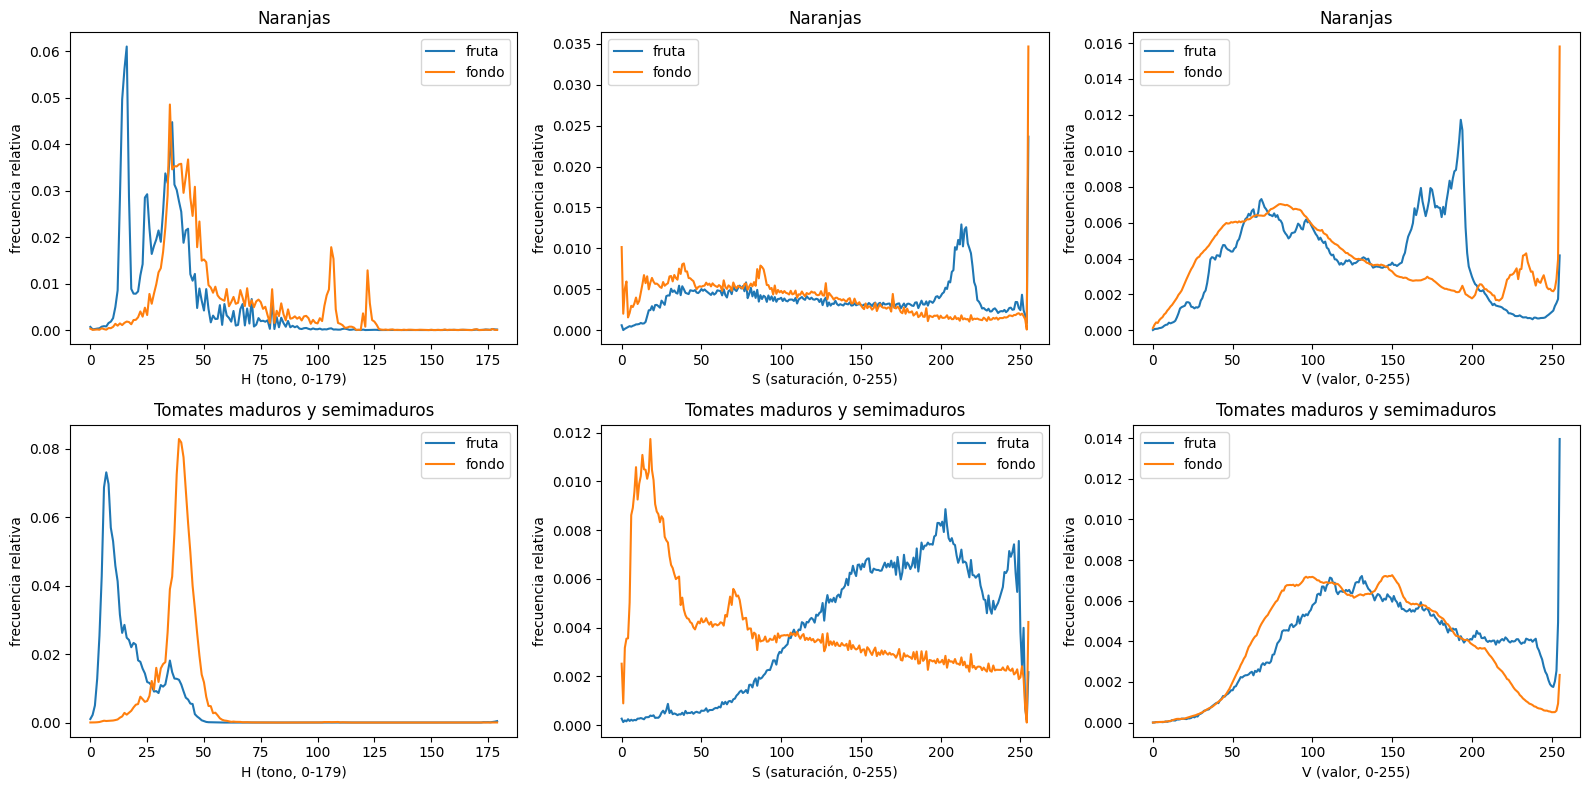

In [ ]:
def histograma_hsv(datos, clases_fruta, s_min=60):
    """Histogramas normalizados de H, S y V dentro de las frutas de las clases indicadas y en el fondo.
    Se usa la elipse inscripta en cada caja, que aproxima mejor la fruta que el rectángulo.
    El filtro de saturación (S > s_min) se aplica solo a H: con S baja el tono no tiene significado."""
    tamanos = (180, 256, 256)                              # H en [0, 179]; S y V en [0, 255]
    h_fruta = [np.zeros(n) for n in tamanos]
    h_fondo = [np.zeros(n) for n in tamanos]
    for d in datos:
        hsv = cv2.cvtColor(d['img'], cv2.COLOR_BGR2HSV)
        fruta = np.zeros(hsv.shape[:2], np.uint8)
        otras = np.zeros(hsv.shape[:2], np.uint8)          # frutas de otras clases: no cuentan como fondo
        for (x, y, w, h), clase in zip(d['cajas'], d['clases']):
            destino = fruta if clase in clases_fruta else otras
            cv2.ellipse(destino, (int(x + w / 2), int(y + h / 2)), (int(w / 2), int(h / 2)), 0, 0, 360, 255, -1)
        en_fruta = fruta > 0
        en_fondo = (fruta == 0) & (otras == 0)
        saturado = hsv[:, :, 1] > s_min
        for c in range(3):
            valido = saturado if c == 0 else True
            canal = hsv[:, :, c]
            # np.bincount cuenta cuántos píxeles hay con cada valor (histograma)
            h_fruta[c] += np.bincount(canal[valido & en_fruta], minlength=tamanos[c])
            h_fondo[c] += np.bincount(canal[valido & en_fondo], minlength=tamanos[c])
    return [h / h.sum() for h in h_fruta], [h / h.sum() for h in h_fondo]


TOMATE_MADURO = ('b_fully_ripened', 'l_fully_ripened', 'b_half_ripened', 'l_half_ripened')
NOMBRES = ['H (tono, 0-179)', 'S (saturación, 0-255)', 'V (valor, 0-255)']
plt.figure(figsize=(16, 8))
for i, (titulo, datos, clases) in enumerate([('Naranjas', naranjas, ('naranja',)),
                                             ('Tomates maduros y semimaduros', tomates, TOMATE_MADURO)]):
    h_fruta, h_fondo = histograma_hsv(datos, clases)
    for c in range(3):
        plt.subplot(2, 3, 3 * i + c + 1)
        plt.plot(h_fruta[c], label='fruta')
        plt.plot(h_fondo[c], label='fondo')
        plt.xlabel(NOMBRES[c]), plt.ylabel('frecuencia relativa'), plt.title(titulo), plt.legend()
plt.tight_layout()
plt.show()

Qué se observa con la muestra por defecto:

- **H**: en los tomates, la fruta tiene el pico en H ≈ 5-15 (rojo y naranja) y el fondo en H ≈ 35-45 (verde); están bien separados. En las naranjas hay un pico claro en H ≈ 15, pero también una zona entre 25 y 45 que se superpone con el fondo: son las **naranjas verdes** y las hojas que caen dentro de la elipse.
- **S**: en los tomates la fruta está casi toda por encima de 100 y el fondo se concentra por debajo de 50 (plástico del invernadero, cielo); eso justifica el umbral mínimo de S. En las naranjas la separación es menor.
- **V**: en los tomates las curvas de fruta y fondo casi coinciden: el brillo **no** distingue la fruta del fondo, y por eso el umbral de V es bajo (solo descarta sombras muy oscuras). En las naranjas la fruta es algo más brillante que las hojas, pero eso depende mucho de la iluminación.

Conclusión: **H y S hacen el trabajo y V casi no aporta**, además de ser el canal que más cambia con las sombras. Por eso conviene un espacio de color que separe el color del brillo, en lugar de umbralizar en RGB.

### **3. Segmentación por umbral de color**

Con `cv2.inRange` se marca cada píxel cuyo (H, S, V) cae dentro de un rango. Para el tomate se usan **dos rangos** (los dos extremos del tono rojo) y se unen con un OR. Los umbrales mínimos de S y V descartan zonas grises, blancas y muy oscuras.

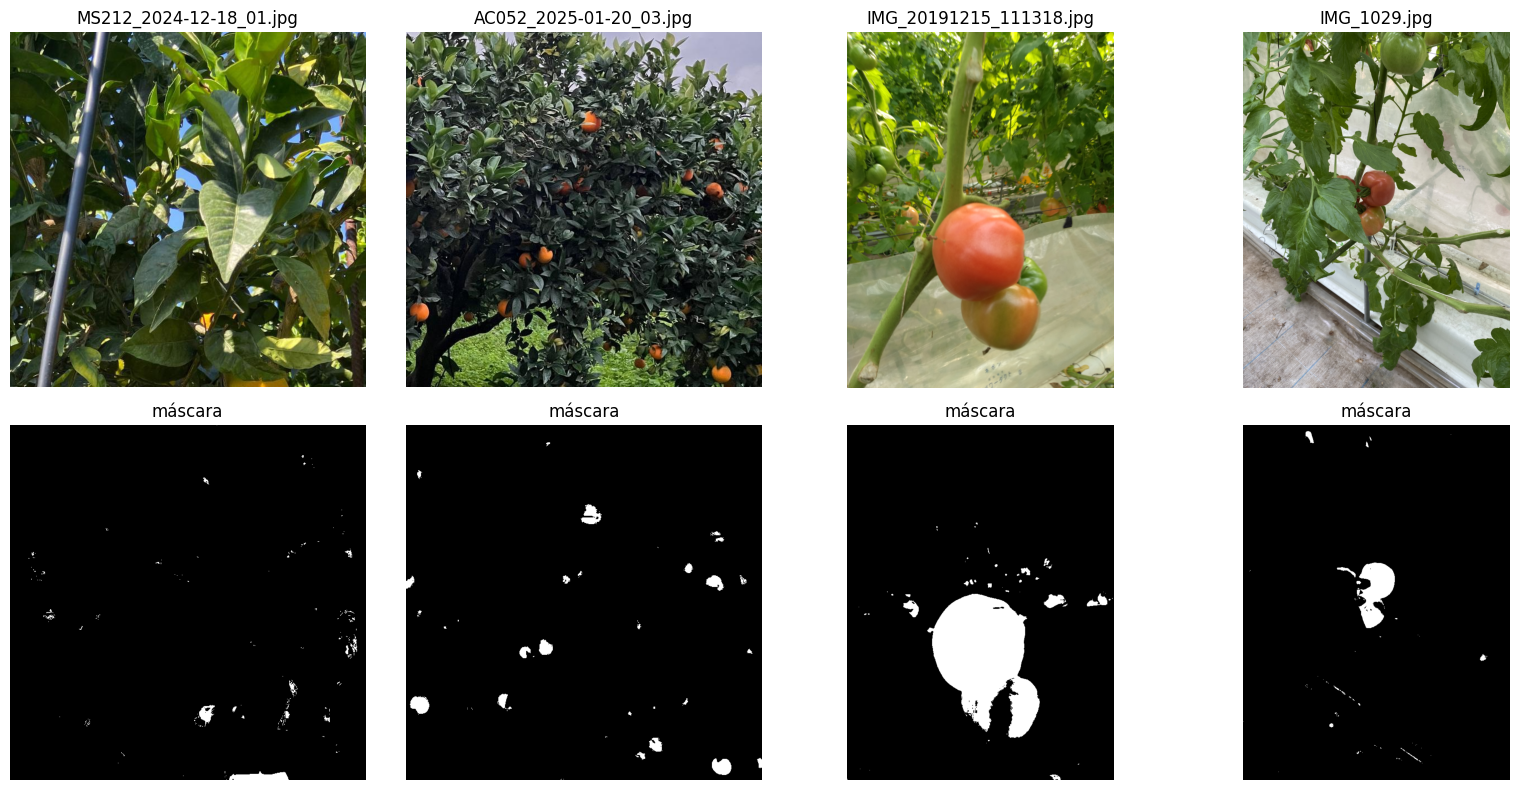

In [ ]:
# Rangos (H, S, V) mínimos y máximos. H en [0, 179]; S y V en [0, 255].
RANGOS = {
    'naranja': [((5, 100, 80), (25, 255, 255))],
    'tomate': [((0, 80, 50), (20, 255, 255)), ((165, 80, 50), (179, 255, 255))],
}


def mascara_hsv(img, rangos):
    """Máscara binaria (0/255) con los píxeles dentro de alguno de los rangos HSV."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    m = np.zeros(img.shape[:2], np.uint8)
    for bajo, alto in rangos:
        m |= cv2.inRange(hsv, bajo, alto)
    return m


ejemplos = [(naranjas[i], 'naranja') for i in range(2)] + [(tomates[i], 'tomate') for i in range(2)]
mostrar([d['img'] for d, _ in ejemplos] + [mascara_hsv(d['img'], RANGOS[f]) for d, f in ejemplos],
        [d['nombre'] for d, _ in ejemplos] + ['máscara'] * 4)

#### 3.1 Ajuste interactivo

Mover los deslizadores para ver cómo cambia la máscara. Probar con imágenes en sombra o a contraluz.

In [ ]:
from ipywidgets import interact, IntSlider

d = naranjas[0]   # cambiar por otra imagen, por ejemplo tomates[3]


@interact(h_min=IntSlider(5, 0, 179, continuous_update=False),
          h_max=IntSlider(25, 0, 179, continuous_update=False),
          s_min=IntSlider(100, 0, 255, continuous_update=False),
          v_min=IntSlider(80, 0, 255, continuous_update=False))
def ajustar(h_min, h_max, s_min, v_min):
    m = mascara_hsv(d['img'], [((h_min, s_min, v_min), (h_max, 255, 255))])
    mostrar([d['img'], m], ['Original', 'Máscara'], columnas=2, tam=6)

interactive(children=(IntSlider(value=5, continuous_update=False, description='h_min', max=179), IntSlider(val…

### **4. Post-procesado morfológico**

La máscara de color tiene ruido (píxeles sueltos del fondo con color parecido) y huecos (brillos especulares, el cáliz, hojas finas delante de la fruta). Se corrige con operaciones morfológicas con un elemento estructurante elíptico, parecido a la forma de la fruta:

- **Erosión**: achica los objetos; elimina los menores que el elemento estructurante.
- **Dilatación**: agranda los objetos; rellena huecos y une partes cercanas.
- **Apertura** = erosión + dilatación: elimina ruido sin cambiar mucho el tamaño de los objetos grandes.
- **Cierre** = dilatación + erosión: rellena huecos y une fragmentos separados por hojas o tallos finos.
- **Relleno de huecos**: se dibujan rellenos los contornos externos.

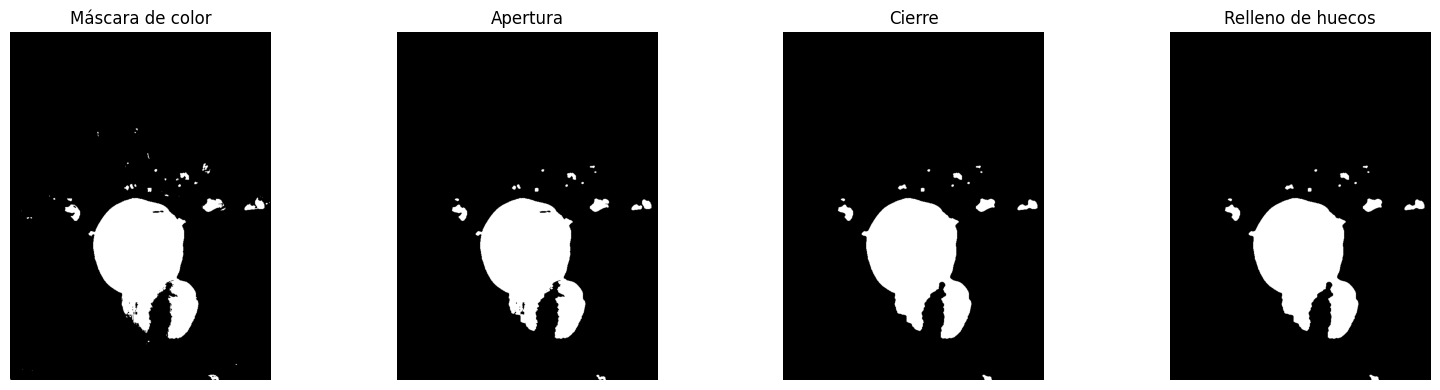

In [ ]:
def rellenar_huecos(m):
    """Rellena los huecos internos dibujando rellenos los contornos externos."""
    contornos, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    salida = np.zeros_like(m)
    cv2.drawContours(salida, contornos, -1, 255, cv2.FILLED)
    return salida


# --------
def limpiar(m, k_apertura=5, k_cierre=11, pasos=False):
    """Apertura, cierre y relleno de huecos. Con pasos=True devuelve también los intermedios."""
    ee_a = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_apertura, k_apertura))
    ee_c = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_cierre, k_cierre))
    abierta = cv2.morphologyEx(m, cv2.MORPH_OPEN, ee_a)
    cerrada = cv2.morphologyEx(abierta, cv2.MORPH_CLOSE, ee_c)
    final = rellenar_huecos(cerrada)
    return (final, [m, abierta, cerrada, final]) if pasos else final


d = tomates[0]
_, etapas = limpiar(mascara_hsv(d['img'], RANGOS['tomate']), pasos=True)
mostrar(etapas, ['Máscara de color', 'Apertura', 'Cierre', 'Relleno de huecos'])

### **5. Separación de frutas que se tocan: transformada de distancia + watershed**

Cuando dos frutas se tocan, en la máscara quedan como **una sola mancha** y los contornos las cuentan como un único objeto. Para separarlas se usan tres pasos.

**Paso 1. Transformada de distancia.** A cada píxel blanco de la máscara se le asigna su distancia (en píxeles) al píxel negro más cercano. Los píxeles del borde valen casi 0 y el centro de cada fruta, que es el punto más alejado del borde, tiene el valor más alto. En la imagen de distancia, cada fruta se ve como una "montaña" con la cima en su centro.

**Paso 2. Semillas.** Se busca la cima de cada montaña, es decir, los máximos locales de la distancia: habrá una semilla por fruta. Un píxel es máximo local si no cambia al dilatar, porque la dilatación reemplaza cada píxel por el máximo de su vecindad. Se descartan las cimas más bajas que `r_min`, que corresponden a frutas demasiado chicas o a ruido.

**Paso 3. Watershed** (en inglés, "divisoria de aguas"). La idea viene de la geografía:

- Se da vuelta la imagen de distancia (se usa **−distancia**): las montañas pasan a ser **pozos**, con el fondo en el centro de cada fruta. Entre dos frutas que se tocan, la zona angosta de la unión (el "cuello") queda como una **loma** más alta que los fondos de los pozos.
- Se empieza a llenar cada pozo con agua desde su semilla, todos al mismo tiempo, subiendo el nivel de a poco. El agua nunca sale de la máscara.
- El agua de cada pozo sube hasta llegar a la loma. Justo donde el agua de un pozo está por mezclarse con la del otro se marca una **frontera**: es la línea que separa las dos frutas, y queda sobre el cuello.

Al final cada píxel de la máscara pertenece a la región de una semilla: una región por fruta.

El ejemplo siguiente lo muestra con dos círculos dibujados a mano. El gráfico del medio es un **corte** del relieve a lo largo de la línea que une los dos centros: se ven los dos pozos, la loma entre ellos y la frontera que encuentra el watershed.

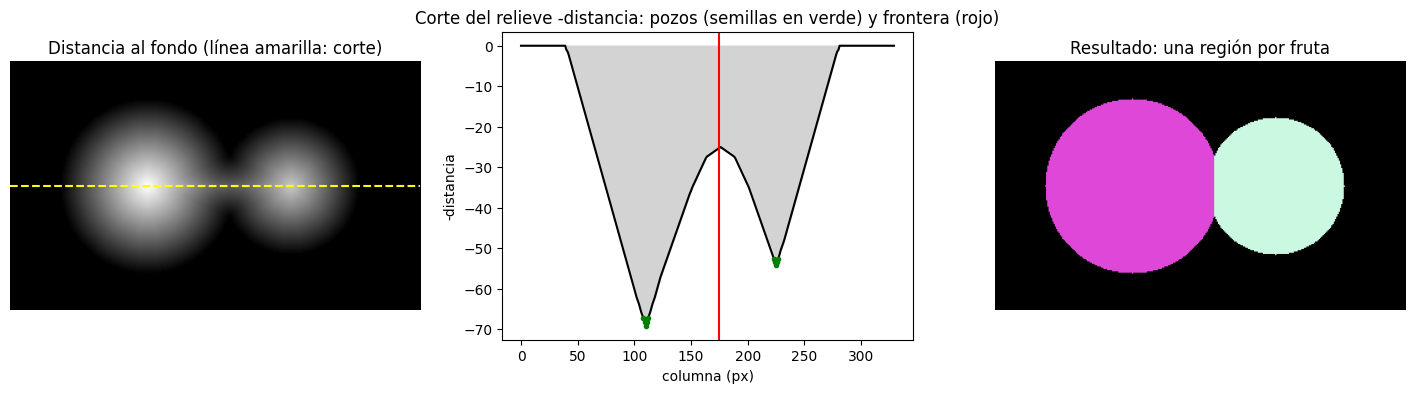

In [ ]:
def separar(m, r_min=8):
    """Devuelve la imagen de etiquetas del watershed (0 = fondo, 1..n = frutas),
    la transformada de distancia y las semillas."""
    # paso 1: distancia de cada píxel de la máscara al fondo
    dist = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    # paso 2: semillas = máximos locales de la distancia, con altura de al menos r_min
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r_min + 1, 2 * r_min + 1))
    semillas = ((dist >= cv2.dilate(dist, ee)) & (dist >= r_min)).astype(np.uint8)
    semillas = cv2.dilate(semillas, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    _, marcadores = cv2.connectedComponents(semillas)       # un número distinto por semilla
    # paso 3: inundar el relieve -dist desde las semillas, sin salir de la máscara
    etiquetas = watershed(-dist, marcadores, mask=m > 0)
    return etiquetas, dist, semillas


# --------
def colorear_etiquetas(marcadores, m):
    """Imagen en colores al azar, una por región, solo dentro de la máscara."""
    colores = np.random.default_rng(0).integers(60, 255, (marcadores.max() + 2, 3), dtype=np.uint8)
    vis = colores[marcadores]
    vis[(m == 0) | (marcadores == 0)] = 0
    return vis


# Ejemplo sintético: dos "frutas" circulares que se tocan
sint = np.zeros((200, 330), np.uint8)
cv2.circle(sint, (110, 100), 70, 255, -1)
cv2.circle(sint, (225, 100), 55, 255, -1)
etq, dist_s, sem_s = separar(sint, r_min=20)

fila = 100                                                   # línea que une los dos centros
frontera = np.where(np.diff(etq[fila]) != 0)[0]              # columnas donde cambia la etiqueta
frontera = [x for x in frontera if etq[fila, x] > 0 and etq[fila, x + 1] > 0]

plt.figure(figsize=(18, 4))
plt.subplot(1, 3, 1)
plt.imshow(dist_s, cmap='gray')
plt.axhline(fila, color='yellow', ls='--')
plt.title('Distancia al fondo (línea amarilla: corte)'), plt.axis('off')
plt.subplot(1, 3, 2)
plt.plot(-dist_s[fila], 'k')
plt.fill_between(range(sint.shape[1]), -dist_s[fila], 0, color='lightgray')
for x in np.where(sem_s[fila] > 0)[0]:
    plt.plot(x, -dist_s[fila, x], 'g.')
for x in frontera:
    plt.axvline(x, color='red')
plt.title('Corte del relieve -distancia: pozos (semillas en verde) y frontera (rojo)')
plt.xlabel('columna (px)'), plt.ylabel('-distancia')
plt.subplot(1, 3, 3)
plt.imshow(colorear_etiquetas(etq, sint)[:, :, ::-1])
plt.title('Resultado: una región por fruta'), plt.axis('off')
plt.show()

**¿Por qué el `watershed` de scikit-image y no el de OpenCV?** Los dos implementan el mismo algoritmo de inundación; la diferencia está en **qué usan como relieve**:

- `skimage.segmentation.watershed(relieve, marcadores, mask)` acepta cualquier imagen como relieve. Se le pasa −distancia, que depende solo de la **forma** de la máscara: la frontera cae en el cuello entre las frutas.
- `cv2.watershed(imagen, marcadores)` solo acepta la imagen color y arma el relieve con los **cambios de color** entre píxeles vecinos. Dos tomates del mismo rojo que se tocan casi no tienen cambio de color entre ellos, así que la frontera puede quedar en cualquier lugar. Al probarlo con estas imágenes, la región de un tomate invadía al vecino.

Ahora sobre una imagen real:

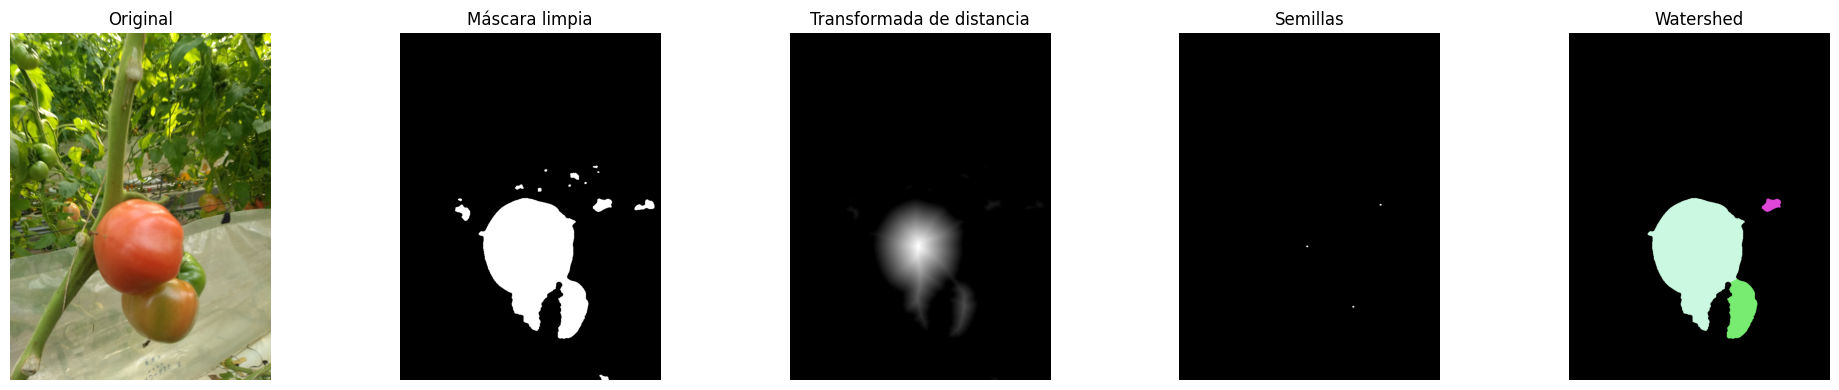

In [ ]:
d = tomates[0]   # dos tomates que se tocan
m = limpiar(mascara_hsv(d['img'], RANGOS['tomate']))
marcadores, dist, semillas = separar(m, r_min=12)
mostrar([d['img'], m, dist, semillas * 255, colorear_etiquetas(marcadores, m)],
        ['Original', 'Máscara limpia', 'Transformada de distancia', 'Semillas', 'Watershed'], columnas=5)

### **6. Descripción de regiones con contornos**

Para cada región se extrae su contorno externo (`cv2.findContours`) y se calculan descriptores de forma:

| Descriptor | Cálculo | Interpretación |
|---|---|---|
| Área $A$ | `cv2.contourArea` | tamaño en píxeles |
| Circularidad | $4\pi A / P^2$ | 1 para un círculo; baja para formas alargadas o irregulares |
| Solidez | $A / A_{\text{envolvente convexa}}$ | menor que 1 si la región tiene "mordidas" (oclusiones) |
| Centroide | momentos $m_{10}/m_{00}$, $m_{01}/m_{00}$ | punto objetivo para el robot |
| Círculo mínimo | `cv2.minEnclosingCircle` | estima la fruta completa aunque esté parcialmente ocluida |

Las regiones con área o circularidad bajas se descartan (hojas secas, ramas, reflejos).

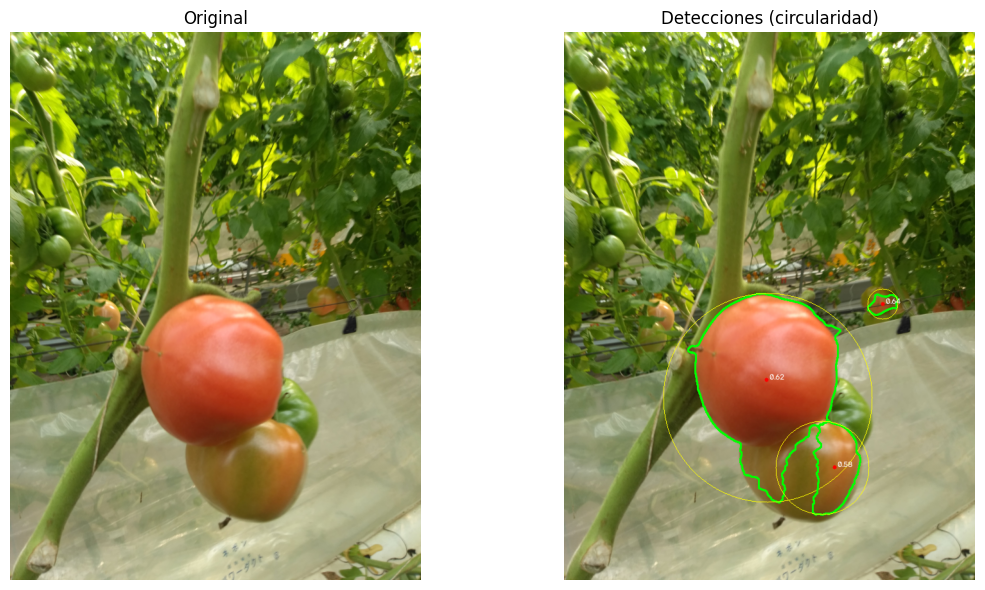

centroide=(496, 423)  area=965  circ=0.64  solidez=0.87  radio=24.5
centroide=(316, 542)  area=47004  circ=0.62  solidez=0.92  radio=163.4
centroide=(421, 678)  area=7621  circ=0.58  solidez=0.91  radio=73.7


In [ ]:
def describir(marcadores, m, area_min=300, circ_min=0.3):
    """Lista de detecciones (diccionarios) con los descriptores de cada región válida."""
    detecciones = []
    for etiqueta in range(1, marcadores.max() + 1):
        region = ((marcadores == etiqueta) & (m > 0)).astype(np.uint8)
        contornos, _ = cv2.findContours(region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contornos:
            continue
        c = max(contornos, key=cv2.contourArea)
        area = cv2.contourArea(c)
        if area < area_min:
            continue
        circularidad = 4 * np.pi * area / cv2.arcLength(c, True) ** 2
        if circularidad < circ_min:
            continue
        solidez = area / cv2.contourArea(cv2.convexHull(c))
        mom = cv2.moments(c)
        (cx, cy), r = cv2.minEnclosingCircle(c)
        detecciones.append({'contorno': c, 'area': area, 'circularidad': circularidad, 'solidez': solidez,
                            'centroide': (mom['m10'] / mom['m00'], mom['m01'] / mom['m00']),
                            'centro': (cx, cy), 'radio': r, 'caja': cv2.boundingRect(c)})
    return detecciones


# --------
def dibujar_detecciones(img, detecciones, texto=True):
    """Contorno (verde), círculo mínimo (amarillo) y centroide (rojo)."""
    vis = img.copy()
    for det in detecciones:
        cv2.drawContours(vis, [det['contorno']], -1, (0, 255, 0), 2)
        cx, cy = map(int, det['centro'])
        cv2.circle(vis, (cx, cy), int(det['radio']), (0, 255, 255), 1)
        gx, gy = map(int, det['centroide'])
        cv2.circle(vis, (gx, gy), 3, (0, 0, 255), -1)
        if texto:
            cv2.putText(vis, f"{det['circularidad']:.2f}", (gx + 5, gy), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)
    return vis


detecciones = describir(marcadores, m)
mostrar([d['img'], dibujar_detecciones(d['img'], detecciones)], ['Original', 'Detecciones (circularidad)'], columnas=2, tam=6)
for det in detecciones:
    print(f"centroide=({det['centroide'][0]:.0f}, {det['centroide'][1]:.0f})  area={det['area']:.0f}  "
          f"circ={det['circularidad']:.2f}  solidez={det['solidez']:.2f}  radio={det['radio']:.1f}")

### **7. Detector completo**

Se juntan todas las etapas en una función. Los parámetros de cada fruta quedan en un diccionario para poder ajustarlos y comparar. `r_min` es mayor para el tomate porque en estas imágenes los tomates aparecen más grandes y más juntos.

In [ ]:
PARAMETROS = {
    'naranja': dict(rangos=RANGOS['naranja'], k_apertura=5, k_cierre=11, r_min=8, area_min=300, circ_min=0.3),
    'tomate': dict(rangos=RANGOS['tomate'], k_apertura=5, k_cierre=11, r_min=12, area_min=300, circ_min=0.3),
}


def detectar_frutas(img, fruta):
    """Detecciones y máscara final para la fruta indicada ('naranja' o 'tomate')."""
    p = PARAMETROS[fruta]
    m = limpiar(mascara_hsv(img, p['rangos']), p['k_apertura'], p['k_cierre'])
    marcadores, _, _ = separar(m, p['r_min'])
    return describir(marcadores, m, p['area_min'], p['circ_min']), m


ejemplos = [(d, 'naranja') for d in naranjas[:4]] + [(d, 'tomate') for d in tomates[:4]]
mostrar([dibujar_detecciones(d['img'], detectar_frutas(d['img'], f)[0], texto=False) for d, f in ejemplos],
        [d['nombre'] for d, _ in ejemplos])

### **8. Alternativa: transformada de Hough para círculos**

Otra forma de encontrar frutas aproximadamente esféricas es buscar círculos con `cv2.HoughCircles` sobre la máscara suavizada. Es útil cuando la fruta está parcialmente tapada, porque basta con ver parte del borde. Su desventaja es que tiene más parámetros sensibles (`param2` es el umbral del acumulador: más bajo implica más círculos, también falsos) y es más costosa computacionalmente.

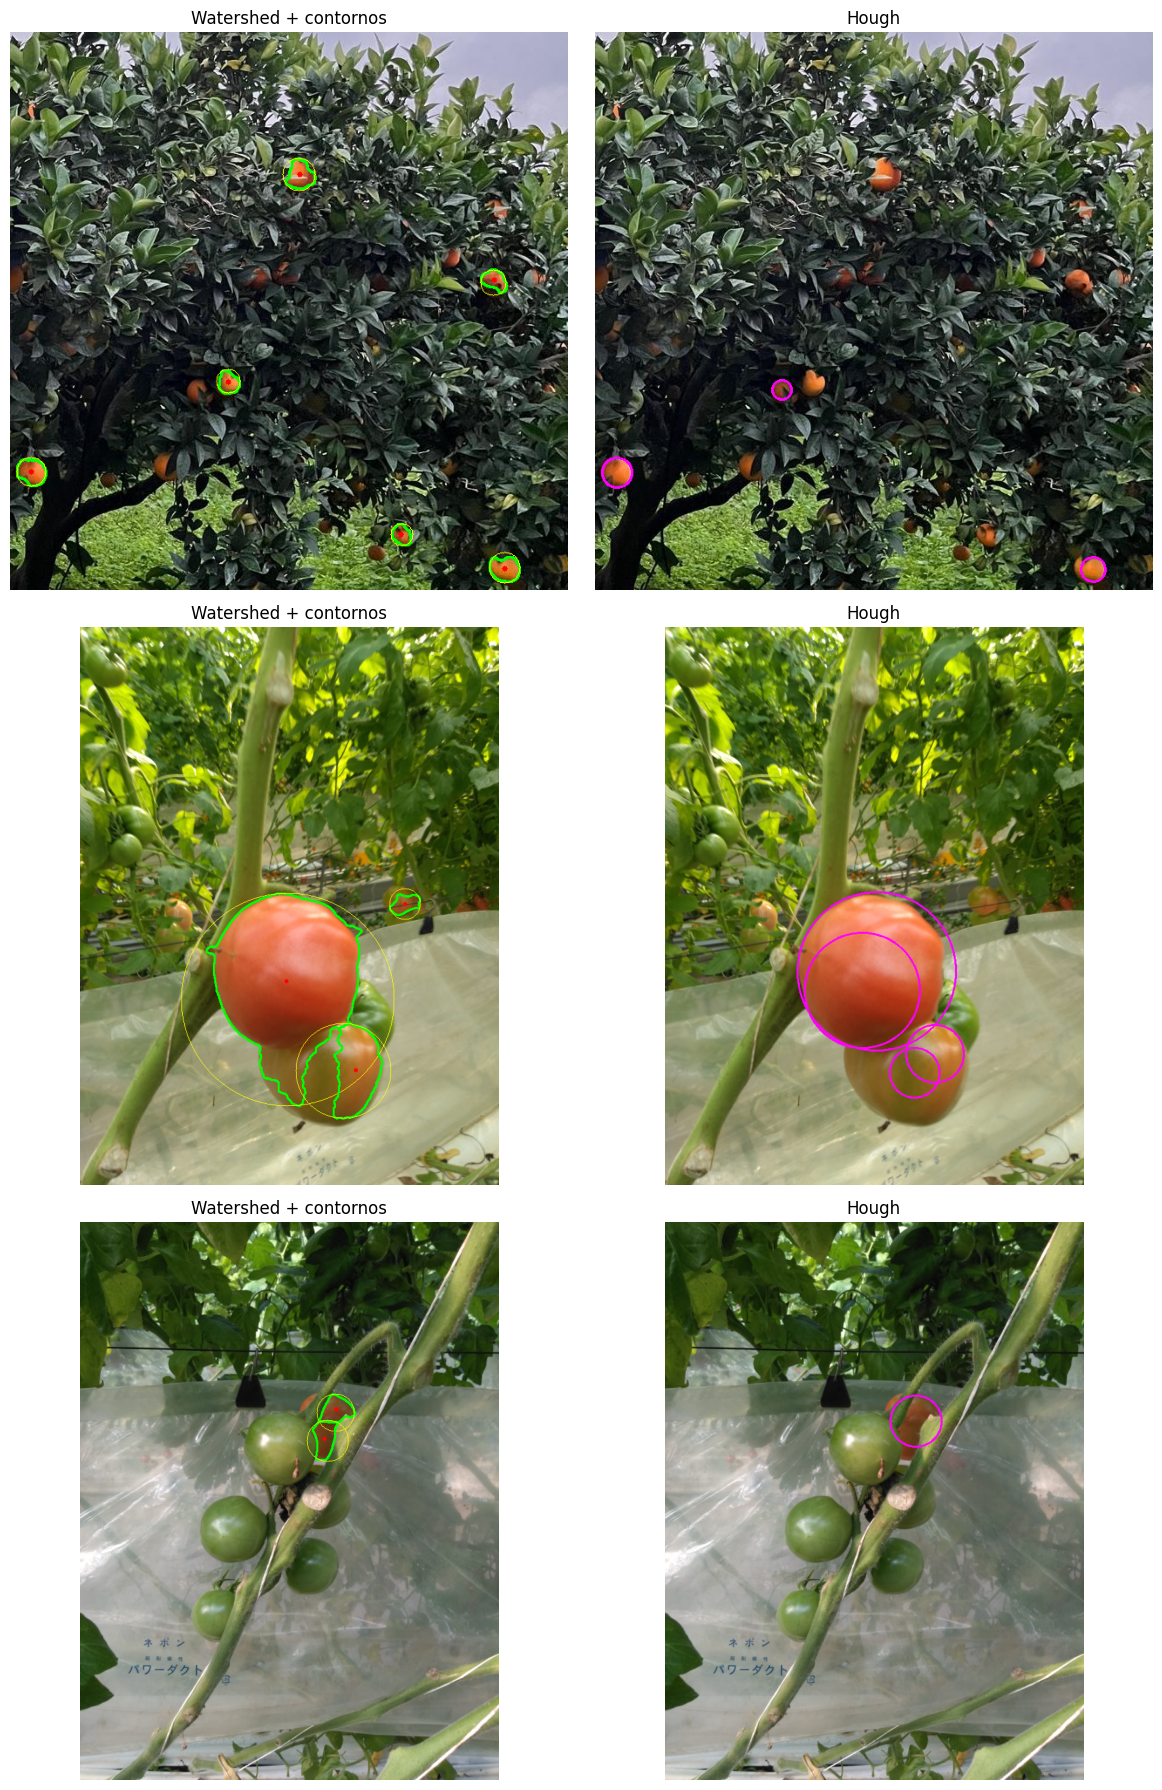

In [ ]:
def hough_circulos(m, r_min=8, r_max=150, param2=30):
    """Círculos (x, y, r) encontrados en la máscara suavizada."""
    suave = cv2.GaussianBlur(m, (9, 9), 2)
    c = cv2.HoughCircles(suave, cv2.HOUGH_GRADIENT, dp=1.2, minDist=3 * r_min,
                         param1=100, param2=param2, minRadius=r_min, maxRadius=r_max)
    return [] if c is None else np.round(c[0]).astype(int)


resultados, titulos = [], []
for d, fruta in [(naranjas[1], 'naranja'), (tomates[0], 'tomate'), (tomates[2], 'tomate')]:
    dets, m = detectar_frutas(d['img'], fruta)
    vis = d['img'].copy()
    for x, y, r in hough_circulos(m, PARAMETROS[fruta]['r_min']):
        cv2.circle(vis, (x, y), r, (255, 0, 255), 2)
    resultados += [dibujar_detecciones(d['img'], dets, texto=False), vis]
    titulos += ['Watershed + contornos', 'Hough']
mostrar(resultados, titulos, columnas=2, tam=6)

### **9. Clasificación por reglas: madurez y tamaño**

#### 9.1 Madurez del tomate

Dentro de cada región se mide la fracción de píxeles rojos (H ≤ 8 o H ≥ 165). Si supera un umbral, el tomate se considera **maduro**; si no, **semimaduro**. En la sección 10 se compara esta regla con las clases de Laboro Tomato.

#### 9.2 Tamaño

El diámetro en píxeles depende de la distancia a la cámara. Con el modelo pinhole, el diámetro real es

$$D = \frac{d_{px} \, Z}{f_{px}}$$

donde $Z$ es la profundidad (que en el trabajo práctico se obtiene con el par estéreo) y $f_{px}$ la distancia focal en píxeles (de la calibración). Por ejemplo, con $f_{px} = 600$ px, $Z = 0{,}40$ m y $d_{px} = 120$ px resulta $D = 0{,}08$ m = 8 cm. Con una sola imagen, sin $Z$, solo se puede comparar el tamaño aparente.

Ejemplo: D = 0.08 m -> grande


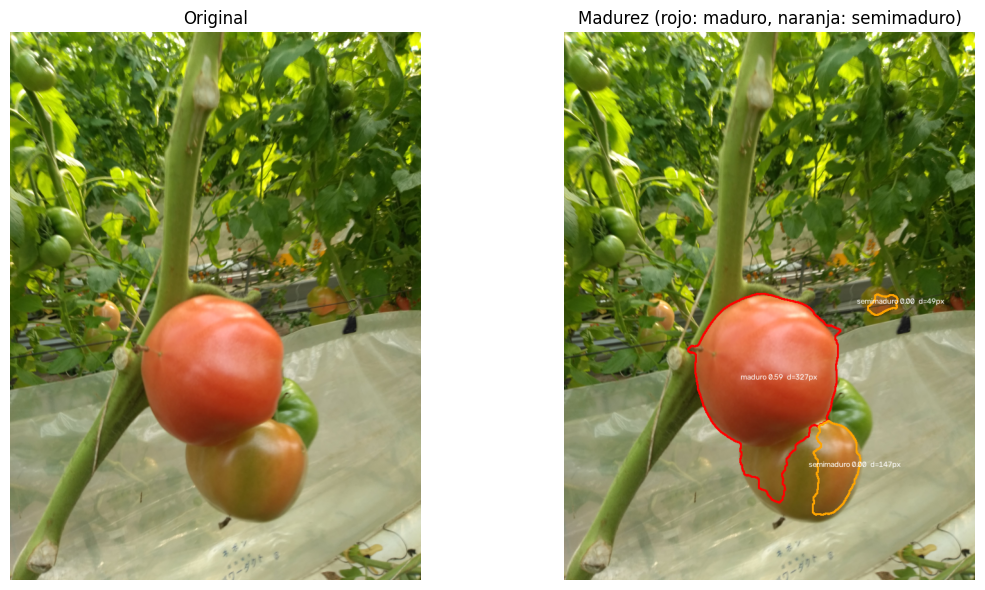

In [ ]:
def madurez_tomate(img, det, umbral=0.5):
    """('maduro' | 'semimaduro', fracción de píxeles rojos) dentro del contorno."""
    region = np.zeros(img.shape[:2], np.uint8)
    cv2.drawContours(region, [det['contorno']], -1, 255, cv2.FILLED)
    h = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[:, :, 0][region > 0]
    fraccion = np.mean((h <= 8) | (h >= 165))
    return ('maduro' if fraccion >= umbral else 'semimaduro'), fraccion


# --------
def diametro_real(d_px, z_m, f_px):
    """Diámetro real (m) a partir del diámetro en píxeles, la profundidad Z (m) y la focal (px)."""
    return d_px * z_m / f_px


# --------
def cajon(d_m, umbral_m=0.07):
    """Regla de clasificación por tamaño: dos cajones."""
    return 'grande' if d_m >= umbral_m else 'chico'


print('Ejemplo: D =', diametro_real(120, 0.40, 600), 'm ->', cajon(diametro_real(120, 0.40, 600)))

d = tomates[0]
dets, _ = detectar_frutas(d['img'], 'tomate')
vis = d['img'].copy()
for det in dets:
    estado, fr = madurez_tomate(d['img'], det)
    color = (0, 0, 255) if estado == 'maduro' else (0, 165, 255)
    cv2.drawContours(vis, [det['contorno']], -1, color, 2)
    gx, gy = map(int, det['centroide'])
    cv2.putText(vis, f'{estado} {fr:.2f}  d={2 * det["radio"]:.0f}px', (gx - 40, gy),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)
mostrar([d['img'], vis], ['Original', 'Madurez (rojo: maduro, naranja: semimaduro)'], columnas=2, tam=6)

### **10. Evaluación contra las anotaciones**

Mirar las imágenes da una idea, pero para comparar dos versiones del detector (otros umbrales, otro espacio de color) hace falta un **número**. Las bases de datos traen la posición de cada fruta marcada a mano: se compara lo que encuentra el detector con esas anotaciones.

Hacen falta dos cosas:

1. Un criterio para decidir si **una** detección coincide con **una** fruta anotada: el IoU.
2. Medidas que resuman **todas** las detecciones de todas las imágenes: precisión, exhaustividad y F1.

#### 10.1 Intersección sobre unión (IoU)

El IoU mide cuánto se superponen dos cajas: la del detector (A) y la anotada (B).

$$\text{IoU} = \frac{\text{área}(A \cap B)}{\text{área}(A \cup B)} = \frac{\text{área}(A \cap B)}{\text{área}(A) + \text{área}(B) - \text{área}(A \cap B)}$$

- Vale **1** si las cajas coinciden exactamente y **0** si no se tocan.
- Se fija un **umbral**: si el IoU lo supera, la detección cuenta como acierto. El valor habitual es **0,5**.

Ejemplo: dos cajas de 100 px² que comparten 60 px². La unión es 100 + 100 − 60 = 140 px², y el IoU es 60 / 140 ≈ 0,43. Con umbral 0,5 **no** cuenta como acierto.

¿Por qué no usar directamente el área compartida? Porque una caja enorme que cubre media imagen siempre "compartiría" área con la fruta. Al dividir por la unión, el IoU castiga tanto quedarse corto como pasarse.

Esto importa en las imágenes de campo: la anotación encierra la fruta **completa**, aunque esté tapada por hojas, y el detector solo ve la parte **visible**. Una fruta bien localizada puede quedar por debajo de 0,5. Por eso más abajo se muestran resultados con 0,5 y con 0,3.

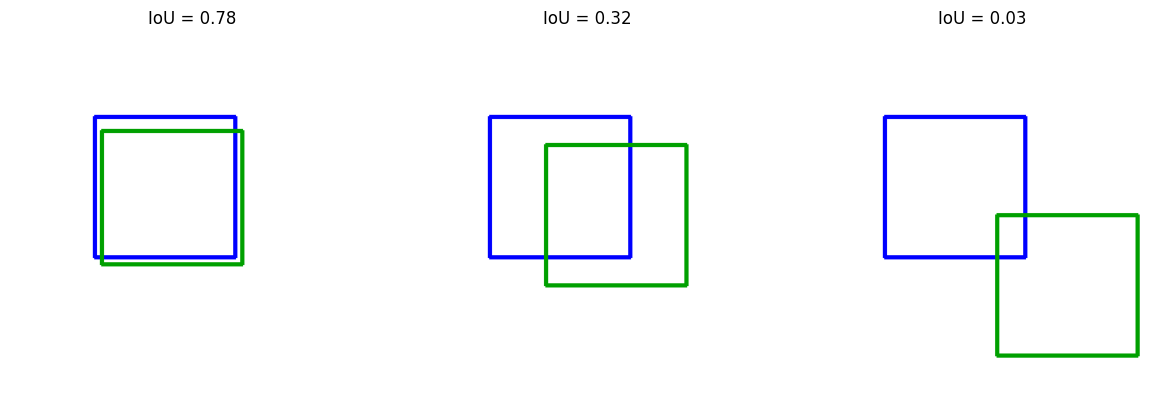

In [ ]:
def iou(a, b):
    """Intersección sobre unión de dos cajas (x, y, w, h)."""
    # ancho y alto de la intersección (0 si no se superponen)
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / (a[2] * a[3] + b[2] * b[3] - inter)


# Ejemplo: caja anotada (azul) y tres posibles detecciones (verde)
anotada = (60, 60, 100, 100)
detecciones_ejemplo = [(65, 70, 100, 95), (100, 80, 100, 100), (140, 130, 100, 100)]
imagenes = []
for det in detecciones_ejemplo:
    lienzo = np.full((260, 260, 3), 255, np.uint8)
    lienzo = dibujar_cajas(lienzo, [anotada], (255, 0, 0))
    lienzo = dibujar_cajas(lienzo, [det], (0, 160, 0))
    imagenes.append(lienzo)
mostrar(imagenes, [f'IoU = {iou(anotada, d):.2f}' for d in detecciones_ejemplo], columnas=3, tam=4)

#### 10.2 Verdaderos y falsos positivos, precisión, exhaustividad y F1

Con el umbral de IoU, cada detección y cada fruta anotada cae en una de tres categorías:

| | Hay fruta anotada | No hay fruta anotada |
|---|---|---|
| **El detector marca algo** | **VP**: verdadero positivo (acierto) | **FP**: falso positivo (por ejemplo, una hoja seca) |
| **El detector no marca nada** | **FN**: falso negativo (fruta no encontrada) | no se cuenta: es todo el resto de la imagen |

A partir de los conteos se calculan dos medidas; cada una responde una pregunta distinta:

- **Precisión**: de lo que detecté, ¿cuánto era fruta?

$$P = \frac{VP}{VP + FP}$$

- **Exhaustividad** (*recall*): de las frutas que había, ¿cuántas encontré?

$$R = \frac{VP}{VP + FN}$$

Las dos tiran en sentidos opuestos. Si se afloja el umbral de color, se detectan más frutas (sube R), pero también más hojas y ramas (baja P). Un detector que marca toda la imagen tiene R = 1 y P casi 0; uno que marca una sola fruta segura tiene P = 1 y R casi 0.

El **F1** resume ambas en un solo número. Es la **media armónica** de P y R:

$$F_1 = \frac{2 \, P \, R}{P + R}$$

La media armónica castiga el desequilibrio: un F1 alto exige que P **y** R sean altos a la vez.

Para el robot del trabajo práctico conviene priorizar la **precisión**: es peor mandar el brazo a cortar una hoja que dejar una fruta para la próxima pasada.

In [ ]:
# Media aritmética contra media armónica (F1) para distintos pares (P, R)
print('    P     R   media    F1')
for P, R in [(0.9, 0.9), (0.6, 0.6), (1.0, 0.1), (0.1, 1.0), (0.8, 0.4)]:
    print(f'{P:5.2f} {R:5.2f}  {(P + R) / 2:6.2f} {2 * P * R / (P + R):5.2f}')

    P     R   media    F1
 0.90  0.90    0.90  0.90
 0.60  0.60    0.60  0.60
 1.00  0.10    0.55  0.18
 0.10  1.00    0.55  0.18
 0.80  0.40    0.60  0.53


Para evaluar un conjunto de imágenes:

1. Se calcula el IoU de cada detección con cada fruta anotada de la misma imagen.
2. Se emparejan de a pares, empezando por el IoU más alto. Cada detección y cada fruta se usan una sola vez, para que dos detecciones sobre la misma fruta no cuenten como dos aciertos.
3. Los pares con IoU ≥ umbral son VP; las detecciones sin pareja son FP y las frutas sin pareja, FN.
4. Se suman VP, FP y FN de todas las imágenes y se calculan P, R y F1.

Para ser justos con el detector se dejan fuera las frutas anotadas con caja menor que `area_min` y, en los tomates, las de clase verde, que este detector por color no busca.

In [ ]:
def emparejar(detecciones, cajas, umbral=0.5):
    """Emparejamiento voraz por IoU decreciente. Devuelve [(i_det, j_caja)], FP (índices) y FN (índices)."""
    pares = sorted(((iou(det['caja'], c), i, j) for i, det in enumerate(detecciones) for j, c in enumerate(cajas)),
                   reverse=True)
    usadas_d, usadas_c, vp = set(), set(), []
    for v, i, j in pares:
        if v < umbral:
            break
        if i not in usadas_d and j not in usadas_c:
            usadas_d.add(i)
            usadas_c.add(j)
            vp.append((i, j))
    fp = [i for i in range(len(detecciones)) if i not in usadas_d]
    fn = [j for j in range(len(cajas)) if j not in usadas_c]
    return vp, fp, fn


# --------
def evaluar(datos, fruta, clases_validas, umbral=0.5):
    """Precisión, exhaustividad y F1 sobre todo el conjunto, y los resultados por imagen."""
    VP = FP = FN = 0
    por_imagen = []
    for d in datos:
        dets, _ = detectar_frutas(d['img'], fruta)
        sel = [k for k, (c, cl) in enumerate(zip(d['cajas'], d['clases']))
               if cl in clases_validas and c[2] * c[3] >= PARAMETROS[fruta]['area_min']]
        cajas = [d['cajas'][k] for k in sel]
        vp, fp, fn = emparejar(dets, cajas, umbral)
        VP, FP, FN = VP + len(vp), FP + len(fp), FN + len(fn)
        por_imagen.append({'d': d, 'dets': dets, 'cajas': cajas, 'clases': [d['clases'][k] for k in sel],
                           'vp': vp, 'fp': fp, 'fn': fn})
    P = VP / max(VP + FP, 1)
    R = VP / max(VP + FN, 1)
    F1 = 2 * P * R / max(P + R, 1e-9)
    return (P, R, F1, VP, FP, FN), por_imagen


for fruta, datos, clases in [('naranja', naranjas, ('naranja',)), ('tomate', tomates, TOMATE_MADURO)]:
    for umbral in (0.5, 0.3):
        (P, R, F1, VP, FP, FN), _ = evaluar(datos, fruta, clases, umbral)
        print(f'{fruta:8s} IoU>={umbral}:  P={P:.2f}  R={R:.2f}  F1={F1:.2f}   (VP={VP}, FP={FP}, FN={FN})')

naranja  IoU>=0.5:  P=0.56  R=0.19  F1=0.29   (VP=45, FP=36, FN=186)
naranja  IoU>=0.3:  P=0.67  R=0.23  F1=0.35   (VP=54, FP=27, FN=177)
tomate   IoU>=0.5:  P=0.38  R=0.49  F1=0.43   (VP=40, FP=65, FN=41)
tomate   IoU>=0.3:  P=0.48  R=0.62  F1=0.54   (VP=50, FP=55, FN=31)


In [ ]:
# Resultados sobre algunas imágenes: VP verde, FP rojo, FN azul
def dibujar_evaluacion(r):
    vis = r['d']['img'].copy()
    for i, _ in r['vp']:
        vis = dibujar_cajas(vis, [r['dets'][i]['caja']], (0, 255, 0))
    vis = dibujar_cajas(vis, [r['dets'][i]['caja'] for i in r['fp']], (0, 0, 255))
    return dibujar_cajas(vis, [r['cajas'][j] for j in r['fn']], (255, 0, 0))


_, res_nar = evaluar(naranjas, 'naranja', ('naranja',))
_, res_tom = evaluar(tomates, 'tomate', TOMATE_MADURO)
ejemplos = res_nar[:4] + res_tom[:4]
mostrar([dibujar_evaluacion(r) for r in ejemplos],
        [f"{r['d']['nombre']}  VP={len(r['vp'])} FP={len(r['fp'])} FN={len(r['fn'])}" for r in ejemplos])

#### 10.3 Compromiso entre precisión y exhaustividad

Cada parámetro del detector mueve el punto de equilibrio entre P y R. Por ejemplo, `circ_min` (la circularidad mínima para aceptar una región): con un valor bajo se acepta casi todo (más frutas, pero también hojas y ramas); con un valor alto solo quedan regiones muy redondas (menos errores, pero se pierden frutas tapadas). Se elige el valor que da el mejor F1, o el que da la precisión que necesita la aplicación.

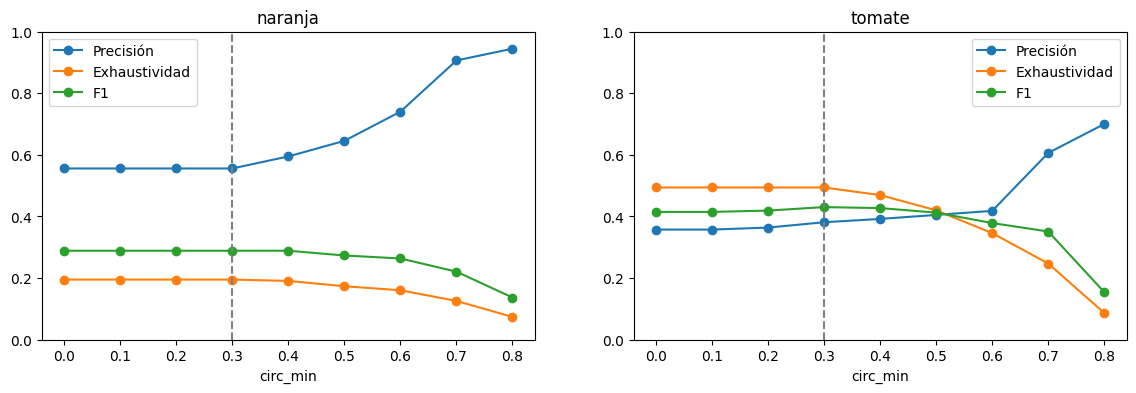

In [ ]:
valores = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
plt.figure(figsize=(14, 4))
for k, (fruta, datos, clases) in enumerate([('naranja', naranjas, ('naranja',)), ('tomate', tomates, TOMATE_MADURO)]):
    original = PARAMETROS[fruta]['circ_min']
    curvas = []
    for v in valores:
        PARAMETROS[fruta]['circ_min'] = v
        curvas.append(evaluar(datos, fruta, clases)[0][:3])
    PARAMETROS[fruta]['circ_min'] = original          # se restaura el valor del detector
    curvas = np.array(curvas)
    plt.subplot(1, 2, k + 1)
    for c, nombre in enumerate(['Precisión', 'Exhaustividad', 'F1']):
        plt.plot(valores, curvas[:, c], 'o-', label=nombre)
    plt.axvline(original, color='gray', ls='--')
    plt.xlabel('circ_min'), plt.ylim(0, 1), plt.title(fruta), plt.legend()
plt.show()

#### 10.4 Madurez: matriz de confusión

Para la regla de madurez se usan solo los tomates bien detectados (los VP) y se compara la predicción con la clase anotada. La **matriz de confusión** cuenta cada combinación (anotación, predicción): en la diagonal están los aciertos y fuera de ella los errores. La **exactitud** es la fracción de aciertos sobre el total.

In [ ]:
# Regla de madurez contra las clases de Laboro Tomato (solo tomates bien detectados)
confusion = np.zeros((2, 2), int)        # filas: anotación (maduro, semimaduro); columnas: predicción
for r in res_tom:
    for i, j in r['vp']:
        real = 0 if 'fully' in r['clases'][j] else 1
        pred = 0 if madurez_tomate(r['d']['img'], r['dets'][i])[0] == 'maduro' else 1
        confusion[real, pred] += 1

print('                  pred. maduro  pred. semimaduro')
print(f'anot. maduro      {confusion[0, 0]:12d}  {confusion[0, 1]:16d}')
print(f'anot. semimaduro  {confusion[1, 0]:12d}  {confusion[1, 1]:16d}')
print(f'Exactitud: {np.trace(confusion) / max(confusion.sum(), 1):.2f}')

                  pred. maduro  pred. semimaduro
anot. maduro                15                 6
anot. semimaduro             1                18
Exactitud: 0.82


### **11. Análisis de resultados**

Con la muestra que se descarga por defecto (40 imágenes de naranjas de Mendeley y 20 de tomates) se obtuvo:

| Fruta | IoU ≥ 0,5: P / R / F1 | IoU ≥ 0,3: P / R / F1 |
|---|---|---|
| Naranja | 0,56 / 0,19 / 0,29 | 0,67 / 0,23 / 0,35 |
| Tomate (maduro y semimaduro) | 0,38 / 0,49 / 0,43 | 0,48 / 0,62 / 0,54 |

La regla de madurez acertó en el 82 % de los tomates bien detectados. Los valores cambian con la muestra (otro `n`, otra `semilla` u otra fuente de imágenes). Las principales causas de error se ven en las imágenes de la sección 10:

- **Frutas verdes**: en una muestra de prueba, cerca del 30 % de las naranjas anotadas no tenían color naranja. Un detector por color no las puede ver; habría que usar forma (Hough sobre bordes) o textura.
- **Oclusión por hojas**: la anotación encierra la fruta completa y el detector ve solo la parte visible, entonces el IoU baja aunque la fruta esté bien localizada. Con IoU ≥ 0,3 los números mejoran.
- **Iluminación**: sombras fuertes, contraluz e imágenes nocturnas cambian S y V. Se puede mejorar ecualizando V (CLAHE) antes de segmentar.
- **Frutas lejanas y muy juntas**: los racimos de tomates cherry se unen en una sola región o quedan por debajo de `area_min`.
- **Máscara incompleta**: en un tomate semimaduro solo una parte supera el umbral de color; esa parte puede quedar unida a un tomate vecino (ver la sección 6). La solidez baja y el círculo mínimo exagerado lo delatan.
- **Falsos positivos**: hojas secas, ramas o el suelo con colores parecidos.

Para el trabajo práctico la situación es más favorable que en estas bases de datos: la escena es **estructurada** (iluminación controlada, fondo conocido, frutas a 30-60 cm de la cámara), y conviene diseñar el escenario para que el color de la fruta contraste con el fondo.

### **12. Ejercicios propuestos**

1. Reemplazar el umbral HSV por el canal **a\*** del espacio Lab (`cv2.COLOR_BGR2LAB`) con umbral de Otsu, y comparar F1.
2. Aplicar **CLAHE** al canal V antes de segmentar y medir el efecto en las imágenes con sombras.
3. Probar distintos valores de `k_cierre` y `r_min` y graficar precisión y exhaustividad en función de cada uno.
4. Adaptar los rangos para **limón** o **frutilla** usando el histograma de la sección 2.1 con imágenes propias.
5. Detectar frutas verdes combinando bordes (Canny) y `cv2.HoughCircles`.
6. Con un par de imágenes estéreo calibradas, calcular la profundidad $Z$ del centroide de cada fruta y clasificarla por diámetro real en dos cajones.

---
### **Referencias**

1. Brunetti, F. *Visión Artificial* — Robótica 1, Ing. Mecatrónica, FIUNA. Presentación de clase. [Enlace](https://docs.google.com/presentation/d/1P8ojM73vEO3ZtscFJnkH8ZQmd0ru0Q6AEFwVPNjiOUc/edit?usp=sharing)
2. Lucas, B., Carella, A., El Ghazouali, S., Bulacio, P., Massenti, R., Venturini, F., Michelucci, U., & Lo Bianco, R. (2025). *Oranges in the field* (versión 1) [Conjunto de datos]. Mendeley Data. https://doi.org/10.17632/93f32zgkxz.1 — Licencia CC BY-NC 3.0.
3. Sa, I., Ge, Z., Dayoub, F., Upcroft, B., Perez, T., & McCool, C. (2016). DeepFruits: A fruit detection system using deep neural networks. *Sensors*, 16(8), 1222. https://doi.org/10.3390/s16081222 — Imágenes disponibles en Hugging Face (proyecto AgML): https://huggingface.co/datasets/Project-AgML/fruit_detection_worldwide
4. Laboro.AI (2020). *Laboro Tomato: Instance Segmentation Dataset*. https://github.com/laboroai/LaboroTomato — Licencia CC BY-NC-SA 4.0.
5. OpenCV. *Changing Colorspaces*. https://docs.opencv.org/4.x/df/d9d/tutorial_py_colorspaces.html
6. OpenCV. *Morphological Transformations*. https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html
7. OpenCV. *Image Segmentation with Watershed Algorithm*. https://docs.opencv.org/4.x/d3/db4/tutorial_py_watershed.html
8. OpenCV. *Contour Features* y *Contour Properties*. https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html — https://docs.opencv.org/4.x/d1/d32/tutorial_py_contour_properties.html
9. OpenCV. *Hough Circle Transform*. https://docs.opencv.org/4.x/da/d53/tutorial_py_houghcircles.html
10. Beucher, S., & Meyer, F. (1993). The morphological approach to segmentation: the watershed transformation. En E. R. Dougherty (Ed.), *Mathematical Morphology in Image Processing* (pp. 433–481). Marcel Dekker.
11. Gongal, A., Amatya, S., Karkee, M., Zhang, Q., & Lewis, K. (2015). Sensors and systems for fruit detection and localization: A review. *Computers and Electronics in Agriculture*, 116, 8–19. https://doi.org/10.1016/j.compag.2015.05.021
12. Gonzalez, R. C., & Woods, R. E. (2018). *Digital Image Processing* (4.ª ed.). Pearson. Caps. 6 (color), 9 (morfología) y 10 (segmentación).
13. Corke, P. (2023). *Robotics, Vision and Control: Fundamental Algorithms in Python* (3.ª ed.). Springer. https://petercorke.com/books/robotics-vision-control-all-versions/
14. remotezip (biblioteca de Python). https://pypi.org/project/remotezip/